# Backpropagation: Derivatives Through a Computation Graph

## 1. Introduction and learning objectives

A neural network is a composition: matrix products feed into nonlinear functions, which feed into another prediction and finally a scalar loss. Backpropagation computes how each earlier parameter affects that final loss by reusing local derivatives. It is a differentiation procedure. Gradient descent is a separate procedure that uses the resulting derivatives.

You will move from scalar chain rules to shared computation paths, derive the reverse pass of a one-hidden-layer network, track every array dimension, and check analytical derivatives using finite differences. You will implement the derivatives yourself; the notebook supplies theory, worked numerical examples, and visual demonstrations, with optional worked solutions below the learner answer cells.

Recommended prerequisites: the gradients in [Logistic Regression](../01-ml-fundamentals/logistic-regression.ipynb) and the representation limits in [Perceptron](perceptron.ipynb). Independently, you need basic algebra and matrix multiplication. The derivative rules and network notation needed here are developed before their exercises.

Try each exercise in its dedicated answer cell first. A collapsed **Show hint** and a separate **Show worked solution — try the exercise first** follow immediately below it. Reference Python is displayed text and is not executed by Run All; some snippets name earlier references in this chapter.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 5.01 — Distinguish differentiation from training

**Type:** Conceptual · **Answer:** Markdown

A program computes exact derivatives of a network's loss but never changes a parameter. Has it trained the network? Explain what an optimizer would still need, and why changing an optimizer should not change the derivative of the same loss at the same parameters.

**Expected outcome:** A clear separation of the forward computation, differentiation, and parameter update.

**Your response to Exercise 5.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.01**

A derivative describes the current state; a training update changes that state.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.01**

It has differentiated the objective, but has not fitted the parameters through updates. A forward pass evaluates predictions and a scalar loss at current parameters. Backpropagation computes that loss's derivatives at the same state. An optimizer then needs a specified update rule, its settings such as learning rate, and a budget or stopping rule to change parameters using training data.

For a differentiable, fixed objective $J$ at a fixed $\theta$, $\nabla J(\theta)$ is a property of that function and point. Replacing gradient descent with another optimizer changes the update, not this derivative. Changing the batch, regularization term, or parameters changes the function or evaluation point, so the corresponding gradients need not agree.

</details>

## 2. Prerequisites and mathematical foundations

### Local derivatives and the chain rule

For a scalar function $f(t)$, the derivative is the limit of $[f(t+h)-f(t)]/h$ as the nonzero perturbation $h$ approaches zero. For a function of several variables, a partial derivative changes one input while holding the others fixed. A gradient collects these partial derivatives for a scalar output.

Useful local rules are:

| Operation | Local derivative |
| --- | --- |
| $q=u+v$ | $\partial q/\partial u=1$, $\partial q/\partial v=1$ |
| $q=uv$ | $\partial q/\partial u=v$, $\partial q/\partial v=u$ |
| $q=u^2/2$ | $dq/du=u$ |
| $q=e^u$ | $dq/du=e^u$ |
| $q=\log u$, $u>0$ | $dq/du=1/u$ |

Here $u,v,q$ are scalar intermediate values and $\log$ is the natural logarithm, inverse to the exponential $e^u$. A local derivative treats the node's direct inputs as independent even when they share an earlier cause.

If $u$ affects $v$, and $v$ affects final loss $J$, the chain rule gives $dJ/du=(dJ/dv)(dv/du)$. If $u$ affects several immediate successors $v_1,\ldots,v_k$, their contributions add:

$$
\frac{dJ}{du}=\sum_{j=1}^k\frac{\partial J}{\partial v_j}\frac{\partial v_j}{\partial u}.
$$

The index $j$ lists outgoing paths; $\sum$ means add. The total derivative includes all paths. Forgetting one path produces a wrong gradient even if every local derivative was correct.

### Exercise 5.02 — Differentiate two dependent paths

**Type:** Mathematical · **Answer:** Markdown

Let $u=t^2$, $v=3t$, and $J=u+v$. Derive $dJ/dt$ by accumulating contributions from both paths, then by substituting directly into $J$.

**Expected outcome:** Two agreeing derivations that explain why the contributions add.

**Your response to Exercise 5.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.02**

The loss has sensitivity one to both of its inputs.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.02**

The path through $u$ contributes
$$
\frac{\partial J}{\partial u}\frac{du}{dt}=1(2t)=2t,
$$
and the path through $v$ contributes
$$
\frac{\partial J}{\partial v}\frac{dv}{dt}=1(3)=3.
$$
Both effects occur when the same $t$ changes, so they add: $dJ/dt=2t+3$. Direct substitution gives $J=t^2+3t$ and the same derivative. Overwriting the first contribution with the second would discard part of the dependence.

</details>

### Activations and their derivatives

An **activation** is a scalar function applied independently to entries of an array. The sigmoid is $\sigma(z)=1/(1+e^{-z})$, with derivative $\sigma(z)[1-\sigma(z)]$. Differentiating the outside reciprocal and inside exponential gives this expression.

The hyperbolic tangent is $\tanh z=(e^z-e^{-z})/(e^z+e^{-z})$, which lies between minus one and one. Using $\tanh z=2\sigma(2z)-1$ and the chain rule gives $d(\tanh z)/dz=4\sigma(2z)[1-\sigma(2z)]=1-\tanh^2z$.

The rectified linear unit, ReLU, is $\phi(z)=\max(0,z)$. Its derivative is zero for $z<0$ and one for $z>0$. There is no classical derivative at zero. For an implementation we may deliberately choose a value of zero there; a numerical gradient check across that corner should not be interpreted as evidence for a classical derivative.

The symbol $\odot$ will mean entrywise multiplication of equal-shaped arrays. Multiplying by an activation derivative entrywise follows from the activation acting separately on each coordinate. It is not a matrix product.

### Exercise 5.03 — Calculate local sensitivity

**Type:** Numerical · **Answer:** Markdown

At $z=0$, calculate the sigmoid derivative and the tanh derivative. At $z=-2$ and $z=2$, state the ReLU derivatives. Explain why a finite-difference calculation around ReLU at exactly zero needs special interpretation.

**Expected outcome:** A small table distinguishing smooth derivatives from a chosen corner convention.

**Your response to Exercise 5.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.03**

Substitute the activation value into each smooth derivative, and treat the ReLU corner separately.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.03**

| Activation and point | Local derivative | Reason |
| --- | ---: | --- |
| Sigmoid at $0$ | $1/4$ | $\sigma(0)=1/2$, so $\sigma(0)(1-\sigma(0))=1/4$ |
| Tanh at $0$ | $1$ | $1-\tanh^2(0)=1$ |
| ReLU at $-2$ | $0$ | Locally constant zero |
| ReLU at $2$ | $1$ | Locally the identity |

ReLU is not differentiable at zero: its one-sided slopes differ. A central difference at that point gives
$$
\frac{\max(0,\epsilon)-\max(0,-\epsilon)}{2\epsilon}=\frac12.
$$
This is not a classical derivative at the corner. A backward implementation choosing slope zero at zero can therefore disagree with that numerical value without having a smooth-region derivative bug. Check smooth points or explicitly test the chosen corner convention.

</details>

### A matrix maps many paths at once

For a vector-valued intermediate function, a **Jacobian** is the matrix of all output/input partial derivatives. We rarely need to build the whole Jacobian for a neural network. Backpropagation combines the final scalar loss's sensitivities with local operations, computing the required vector–Jacobian products implicitly.

The notation $\mathbb R$ means real numbers, and membership $\in\mathbb R^{n\times d}$ specifies a matrix with $n$ rows and $d$ columns. In this curriculum, examples are matrix rows. For $n$ observations with $d$ features, $X\in\mathbb R^{n\times d}$. For networks with one binary output, labels will be $Y\in\mathbb R^{n\times1}$, explicitly reshaped from earlier notebooks' `(n,)` labels. This column-shaped convention also applies to output probabilities. Subtracting an `(n,)` vector from an `(n, 1)` array would broadcast to `(n, n)` and is a serious bug.

Superscripts in square brackets mark **layers**, not powers. A one-hidden-layer network has two parameterized affine layers:

$$
A^{[0]}=X,\quad
Z^{[1]}=XW^{[1]}+\mathbf1_n(b^{[1]})^T,\quad
A^{[1]}=\phi(Z^{[1]}),
$$
$$
Z^{[2]}=A^{[1]}W^{[2]}+\mathbf1_n(b^{[2]})^T,\quad
P=\sigma(Z^{[2]}).
$$

A superscript $T$ denotes transpose. $Z$ denotes values before activation; $A$ denotes values after activation; $P$ is the matrix of positive-class probabilities. The vector $\mathbf1_n$ contains $n$ ones and repeats the intercept across observations. $\phi$ is the chosen hidden activation.

| Quantity | Shape | Meaning |
| --- | --- | --- |
| $X=A^{[0]}$ | $(n,d)$ | Inputs |
| $W^{[1]}$, $b^{[1]}$ | $(d,h)$, $(h,)$ | Hidden weights and biases |
| $Z^{[1]},A^{[1]}$ | $(n,h)$ | Hidden preactivations and activations |
| $W^{[2]}$, $b^{[2]}$ | $(h,1)$, $(1,)$ | Output weights and bias |
| $Z^{[2]},P,Y$ | $(n,1)$ | Output scores, probabilities, targets |

Here $h$ is the hidden width: its number of units. In formulas, a bias is a mathematical column vector; in NumPy it is stored as a one-dimensional array and broadcast along rows.

### Exercise 5.04 — Audit a matrix multiplication

**Type:** Conceptual · **Answer:** Markdown

For $n=5$, $d=3$, and $h=4$, state the shape of every forward intermediate. Explain why the hidden weight matrix cannot have shape `(4, 3)` under this row-wise convention.

**Expected outcome:** A complete forward shape trace and an explanation of which dimensions must match.

**Your response to Exercise 5.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.04**

The feature count is the inner dimension of the first matrix product.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.04**

| Quantity | Shape |
| --- | --- |
| $X$ | $(5,3)$ |
| $W^{[1]}$, $b^{[1]}$ | $(3,4)$, $(4,)$ |
| $Z^{[1]}$, $A^{[1]}$ | $(5,4)$, $(5,4)$ |
| $W^{[2]}$, $b^{[2]}$ | $(4,1)$, $(1,)$ |
| $Z^{[2]}$, $P$, $Y$ | $(5,1)$ each |

The product $(5,3)@(3,4)$ maps each input row to four hidden coordinates. A first weight matrix shaped $(4,3)$ would require an inner dimension of four and cannot multiply these three-feature rows. Biases broadcast across observations; a one-example batch still retains its leading sample dimension.

</details>

## 3. Theoretical development and worked examples

### Reverse accumulation on a scalar graph

Let $u=ax$, $v=u+a$, and $J=v^2/2$, where $x$ is fixed input and $a$ is a shared parameter. A computation graph records these dependencies without forgetting the direct path from $a$ to $v$. Define the **adjoint** $\bar q=\partial J/\partial q$ as the loss sensitivity of an intermediate $q$.

**Worked example.** With $x=2$ and $a=1$, the forward values are $u=2$, $v=3$, $J=9/2$. Reverse accumulation starts with $\bar J=1$. The square node gives $\bar v=v=3$. The addition gives $\bar u=3$ and a direct contribution of $3$ to $\bar a$. The product adds $\bar u x=6$ to $\bar a$, so $\bar a=3+6=9$. Direct substitution gives $J=a^2(x+1)^2/2$, whose derivative at these values is also nine.

The forward pass caches values needed later, such as $x$ for the product's derivative with respect to $a$. The reverse pass visits operations after their dependents have supplied sensitivities. A shared parameter must **accumulate** contributions; assignment that overwrites the first contribution with the second is wrong.

### Exercise 5.05 — Accumulate a reused parameter

**Type:** Numerical · **Answer:** Markdown

Use the different graph $u=at$, $v=u+a$, and $J=(v-1)^2/2$, with $a=2$ and fixed $t=-1/2$. Compute all forward values and $dJ/da$ through both paths. Check by direct substitution.

**Expected outcome:** A forward table, two derivative contributions, and their sum.

**Your response to Exercise 5.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.05**

Compute the residual before propagating through either path.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.05**

At the specified point, $u=at=2(-1/2)=-1$, $v=u+a=1$, and $J=(v-1)^2/2=0$.

The outer sensitivity is $\partial J/\partial v=v-1=0$. The indirect path through $u$ contributes $(v-1)(1)t=0$, and the direct occurrence of $a$ in $v$ contributes $(v-1)(1)=0$. Their sum is zero.

Direct substitution gives
$$
J(a)=\frac12\left(a(t+1)-1\right)^2,\qquad
\frac{dJ}{da}=\left(a(t+1)-1\right)(t+1),
$$
which is zero at $a=2,t=-1/2$.

This particular zero residual cannot expose a missing-path bug. At $a=1$ with the same $t$, the indirect contribution is $(-1/2)(-1/2)=1/4$, the direct contribution is $-1/2$, and the correct total is $-1/4$. Such a second point is useful for verification.

</details>

### From binary loss to the output sensitivity

Use average binary cross-entropy:

$$
J=-\frac1n\sum_{i=1}^n
\bigl[Y_{i1}\log P_{i1}+(1-Y_{i1})\log(1-P_{i1})\bigr].
$$

For one observation with target $y\in\{0,1\}$, probability $p=\sigma(z)$, and individual loss $\ell$, differentiating with respect to $p$ gives $(p-y)/[p(1-p)]$. Multiplication by $dp/dz=p(1-p)$ cancels the denominator. Thus $\partial\ell/\partial z=p-y$. The loss average then gives

$$
D^{[2]}=\frac{\partial J}{\partial Z^{[2]}}=\frac{P-Y}{n}.
$$

The notation $\partial J/\partial Z$ means the array of entrywise sensitivities of a scalar $J$ to all entries of $Z$, with the same shape as $Z$. We place the averaging factor here **once**. All later products and bias reductions must respect that convention.

For numerical evaluation use the equivalent individual logit loss $\log(1+e^z)-yz$, evaluated with `np.logaddexp(0, z) - y*z`. This avoids logarithms of rounded probabilities. Stable sigmoid evaluation can branch by the sign of the logit, using $e^z/(1+e^z)$ on negative values and $1/(1+e^{-z})$ on nonnegative values.

### Deriving matrix and bias gradients

Consider any affine operation $Z=AW+\mathbf1_n b^T$ with $A$ of shape $(n,r)$ and $W$ of shape $(r,s)$. The positive integers $r,s$ are its input and output widths. For observation $k$ and output $j$,

$$
Z_{kj}=\sum_{i=1}^r A_{ki}W_{ij}+b_j.
$$

Holding $A$ fixed, $\partial Z_{kj}/\partial W_{ij}=A_{ki}$. Since one weight affects every observation, the chain rule adds over $k$. With $D=\partial J/\partial Z$,

$$
\frac{\partial J}{\partial W_{ij}}=\sum_{k=1}^n A_{ki}D_{kj},
\qquad
\nabla_W J=A^TD.
$$

This has shape $(r,n)(n,s)=(r,s)$, matching $W$. Each bias is reused in every row with derivative one, so

$$
(\nabla_b J)_j=\sum_{k=1}^nD_{kj}.
$$

Sum over observations, not features. In NumPy use the reduction axis corresponding to rows and keep the bias gradient shaped like the stored bias. If $D$ already includes $1/n$, these sums need no additional averaging.

For an input entry $A_{ki}$, all output coordinates contribute:

$$
\frac{\partial J}{\partial A_{ki}}=\sum_{j=1}^sD_{kj}W_{ij},
\qquad
\frac{\partial J}{\partial A}=DW^T.
$$

The transpose routes each output's sensitivity back to the inputs contributing to it. Finally, if $A=\phi(Z_{\mathrm{previous}})$, the entrywise chain rule multiplies by $\phi'(Z_{\mathrm{previous}})$.

### The one-hidden-layer reverse pass

Apply those local results from output to input:

$$
\nabla_{W^{[2]}}J=(A^{[1]})^TD^{[2]},\qquad
\nabla_{b^{[2]}}J=\sum_{\text{rows}}D^{[2]},
$$
$$
D^{[1]}=\bigl(D^{[2]}(W^{[2]})^T\bigr)\odot\phi'(Z^{[1]}),
$$
$$
\nabla_{W^{[1]}}J=X^TD^{[1]},\qquad
\nabla_{b^{[1]}}J=\sum_{\text{rows}}D^{[1]}.
$$

The expression $\sum_{\text{rows}}$ sums each column across observations. $D^{[1]}$ has shape $(n,h)$. The gradient matrices have exactly their parameter matrices' shapes. Compute these derivatives using the weights that produced the forward pass; updating $W^{[2]}$ before calculating $D^{[1]}$ mixes two parameter states and no longer differentiates the recorded computation.

**Worked numerical chain.** For a single input $x=2$, hidden weight $0.4$, hidden bias $0.2$, and ReLU activation, the hidden preactivation and activation are both one. With output weight $0.5$ and bias zero, the output logit is $0.5$, probability about $0.622459$, and positive-target loss about $0.474077$. Output sensitivity is approximately $-0.377541$. The output weight and bias gradients are both $-0.377541$. Multiplying by output weight $0.5$ and ReLU derivative one gives hidden sensitivity $-0.1887705$. The hidden weight gradient multiplies this by input two, giving approximately $-0.377541$; its bias gradient is approximately $-0.1887705$. All values refer to the same forward state.

### Exercise 5.06 — Account for a shared bias

**Type:** Mathematical · **Answer:** Markdown

For $Z=AW+\mathbf1_n b^T$, derive the gradient with respect to one bias entry from the component formula. Explain why summing over output columns instead of observations would usually have the wrong dimension.

**Expected outcome:** A component derivation and shape check, including where the loss average has already entered.

**Your response to Exercise 5.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.06**

A single bias entry is reused in every observation of its output column.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.06**

Write $Z_{ij}=\sum_k A_{ik}W_{kj}+b_j$ and $D_{ij}=\partial J/\partial Z_{ij}$. Changing $b_j$ changes each $Z_{ij}$ in column $j$ with derivative one and changes no other column. Thus
$$
\frac{\partial J}{\partial b_j}=\sum_{i=1}^n D_{ij}.
$$
If $Z$ is $(n,s)$, summing axis zero returns $(s,)$, exactly the stored bias shape. Summing across output columns returns $(n,)$, one value per observation, which is not the bias gradient. Equal dimensions can conceal that semantic error.

For the stated mean-loss network, the factor $1/n$ entered the output sensitivity and propagates into downstream $D$. Do not average this row sum again.

</details>

## 4. Guided exercises

### Exercise 5.07 — Trace a different scalar network

**Type:** Numerical · **Answer:** Markdown

Take one example $x=1$, target $y=0$, a tanh hidden unit with weight $1$ and bias $0$, and a sigmoid output with weight $2$ and bias $-1$. Compute the forward values and all four parameter derivatives by hand, using a calculator for tanh and exponentials.

**Expected outcome:** A labeled chain from input to loss and back, with rounded intermediate values and correct gradient signs.

**Your response to Exercise 5.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.07**

For sigmoid cross-entropy the output logit sensitivity is probability minus label.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.07**

There is one observation, so the average contributes no additional scale. Let $h=\tanh(z_1)$ and $p=\sigma(z_2)$.

| Forward quantity | Value |
| --- | ---: |
| $z_1=1(1)+0$ | $1$ |
| $h=\tanh(1)$ | $0.761594156$ |
| $z_2=2h-1$ | $0.523188312$ |
| $p=\sigma(z_2)$ | $0.627892998$ |
| $J=-\log(1-p)$ | $0.988573825$ |

The output sensitivity is $D_2=p-y=p$. Hence
$$
\frac{\partial J}{\partial w_2}=D_2h\approx0.478199637,\qquad
\frac{\partial J}{\partial b_2}=D_2\approx0.627892998.
$$
Propagating through the old output weight and tanh gives
$$
D_1=D_2(2)(1-h^2)\approx0.527397896.
$$
Thus $\partial J/\partial w_1=D_1x\approx0.527397896$ and $\partial J/\partial b_1=D_1\approx0.527397896$. All four derivatives are positive at this state; a sufficiently small negative-gradient step locally lowers the loss.

</details>

### Exercise 5.08 — Verify every reverse shape

**Type:** Mathematical · **Answer:** Markdown

For $n=6$, $d=2$, and hidden width $h=3$, list the shapes in each reverse-pass multiplication above. Explain the effect of a mistaken extra division by $n$ in both weight-gradient expressions.

**Expected outcome:** Matching parameter/gradient shapes and a precise account of the scaling error.

**Your response to Exercise 5.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.08**

Each gradient must have the shape of its parameter, and the output sensitivity already includes the batch average.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.08**

| Computation | Shapes |
| --- | --- |
| $D^{[2]}=(P-Y)/6$ | $(6,1)$ |
| $(A^{[1]})^TD^{[2]}$ | $(3,6)@(6,1)=(3,1)$ |
| $\sum_{\mathrm{rows}}D^{[2]}$ | $(1,)$ |
| $D^{[2]}(W^{[2]})^T$ | $(6,1)@(1,3)=(6,3)$ |
| $D^{[1]}=(D^{[2]}(W^{[2]})^T)\odot(1-(A^{[1]})^2)$ | $(6,3)$ |
| $X^TD^{[1]}$ | $(2,6)@(6,3)=(2,3)$ |
| $\sum_{\mathrm{rows}}D^{[1]}$ | $(3,)$ |

An extra division by six in each weight-gradient expression makes each weight gradient one sixth of the correct derivative, provided the sensitivities themselves are left unchanged. It does not automatically introduce a factor of $1/36$ into the first layer, because reverse propagation uses the old weights, not the weight gradients. Bias gradients remain correct if their sums are unchanged, making this more than a uniform learning-rate adjustment.

</details>

### Checking derivatives numerically

Collect every scalar parameter into a vector $\theta\in\mathbb R^p$, where $p$ counts parameters, using a recorded ordering for flattening and reshaping matrices. Let $e_j$ be the length-$p$ vector with a one in coordinate $j$ and zeros elsewhere. For a small positive perturbation $\epsilon$, the central-difference estimate is

$$
g^{\mathrm{num}}_j
=\frac{J(\theta+\epsilon e_j)-J(\theta-\epsilon e_j)}{2\epsilon}.
$$

The numerator compares losses on either side of the same point. Taylor expansions around that point have opposite first-order terms and equal second-order terms; subtraction cancels the latter, leaving a second-order approximation error when the required smooth derivatives exist. Extremely small $\epsilon$ can worsen floating-point cancellation and roundoff, so smaller is not always better.

One useful whole-vector diagnostic is

$$
E_{\mathrm{rel}}=
\frac{\lVert g^{\mathrm{analytic}}-g^{\mathrm{num}}\rVert_2}
{\max(10^{-12},\lVert g^{\mathrm{analytic}}\rVert_2+\lVert g^{\mathrm{num}}\rVert_2)}.
$$

Here $\lVert v\rVert_2=\sqrt{\sum_jv_j^2}$ is Euclidean vector length and $\max$ selects the larger denominator. Also inspect the largest absolute coordinate error, particularly when both gradient norms are tiny. Try several perturbation sizes. Near ReLU corners, use smooth tanh examples or choose parameters whose preactivations remain away from zero under perturbation.

Gradient checking is a diagnostic, not the training algorithm. Checking all $p$ parameters needs roughly $2p$ loss evaluations, whereas a reverse pass reuses intermediate computations. Hold parameters, data, randomness, loss normalization, and regularization fixed across the compared evaluations.

## 5. Implementation challenges

### Exercise 5.09 — Implement a small shared-parameter graph

**Type:** Programming · **Answer:** Code

Implement the forward and analytical derivative for a scalar graph of your choosing with a parameter used on at least two paths. Write down the graph and expected derivative first, then compare to a central difference at several values.

**Expected outcome:** Evidence that gradient contributions accumulate instead of overwriting one another. Choose a graph different from the worked examples.

In [ ]:
# Your code for Exercise 5.09.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.09**

Use a nonlinear and a linear occurrence of the same scalar before the loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.09**

One possible graph is $u=a^2$, $v=3a$, $r=u+v-2$, and $J=r^2/2$. Its derivative is
$$
J'(a)=r(2a)+r(3)=(a^2+3a-2)(2a+3).
$$
The two contributions must be added before returning the derivative.

~~~python
import numpy as np

def shared_graph(a):
    u, v = a * a, 3 * a
    residual = u + v - 2
    return 0.5 * residual**2, residual * (2 * a + 3)

for ref_a in (-2.0, -0.3, 0.7, 2.0):
    ref_value, ref_derivative = shared_graph(ref_a)
    ref_step = 1e-5
    ref_numeric = (
        shared_graph(ref_a + ref_step)[0]
        - shared_graph(ref_a - ref_step)[0]
    ) / (2 * ref_step)
    print(ref_a, ref_value, ref_derivative, ref_numeric)
    assert np.isclose(ref_derivative, ref_numeric, rtol=1e-7, atol=1e-8)
~~~

</details>

### Exercise 5.10 — Implement the one-hidden-layer forward pass

**Type:** Programming · **Answer:** Code

Write a NumPy forward function for the row-wise network above with tanh hidden units and sigmoid output. Return probabilities and a cache of values needed for differentiation. Evaluate stable average logit cross-entropy separately.

**Expected outcome:** Explicit shape assertions for inputs, targets, weights, biases, and intermediates, with no calls to automatic-differentiation or ML frameworks.

In [ ]:
# Your code for Exercise 5.10.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.10**

Cache the hidden activations and the output weight state used to generate the probabilities.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.10**

This implementation is self-contained. Targets are deliberately absent from prediction; the loss validates them separately. Nonempty batches are required because this chapter evaluates an average loss.

~~~python
import numpy as np

def bp_sigmoid(z):
    z = np.asarray(z, dtype=float)
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result

def network_forward(X, parameters):
    X = np.asarray(X, dtype=float)
    W1, b1, W2, b2 = (
        np.asarray(parameters[name], dtype=float)
        for name in ("W1", "b1", "W2", "b2")
    )
    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        raise ValueError("X must be a nonempty (n, d) matrix")
    if W1.ndim != 2 or W1.shape[0] != X.shape[1] or W1.shape[1] == 0:
        raise ValueError("W1 must have shape (d, h), h > 0")
    if b1.shape != (W1.shape[1],) or W2.shape != (W1.shape[1], 1):
        raise ValueError("hidden bias or output weight shape mismatch")
    if b2.shape != (1,):
        raise ValueError("output bias must have shape (1,)")
    if not all(np.isfinite(a).all() for a in (X, W1, b1, W2, b2)):
        raise ValueError("inputs and parameters must be finite")
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)
    Z2 = A1 @ W2 + b2
    P = bp_sigmoid(Z2)
    assert Z1.shape == A1.shape == (len(X), W1.shape[1])
    assert Z2.shape == P.shape == (len(X), 1)
    cache = {
        "X": X.copy(), "Z1": Z1, "A1": A1, "Z2": Z2, "P": P,
        "W2": W2.copy(),
    }
    return P, cache

def bp_targets(Y, n):
    Y = np.asarray(Y, dtype=float)
    if Y.shape != (n, 1) or not np.isin(Y, [0, 1]).all():
        raise ValueError("Y must be binary with shape (n, 1)")
    return Y

def network_loss(parameters, X, Y):
    P, cache = network_forward(X, parameters)
    Y = bp_targets(Y, len(P))
    logits = cache["Z2"]
    return float(np.mean(np.logaddexp(0, logits) - Y * logits))
~~~

The output logit stays available for a stable loss even when a probability rounds to zero or one. Copying the output weights also makes the reverse snapshot explicit.

</details>

### Exercise 5.11 — Implement a reverse pass

**Type:** Programming · **Answer:** Code

Use your cached forward values to return the four parameter-gradient arrays. Include the loss average exactly once. Do not change any parameter inside this function.

**Expected outcome:** Gradients matching parameter shapes, a reproducible manual-example comparison, and an explanation of which cached values each derivative needs.

In [ ]:
# Your code for Exercise 5.11.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.11**

Start with $(P-Y)/n$, then alternate affine and activation rules.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.11**

Use the helpers from **5.10**. No optimizer update belongs in this function.

~~~python
def network_backward(cache, Y):
    X, A1, P, W2 = (
        cache[name] for name in ("X", "A1", "P", "W2")
    )
    Y = bp_targets(Y, len(X))
    D2 = (P - Y) / len(X)
    D1 = (D2 @ W2.T) * (1 - A1**2)
    gradients = {
        "W2": A1.T @ D2,
        "b2": D2.sum(axis=0),
        "W1": X.T @ D1,
        "b1": D1.sum(axis=0),
    }
    assert gradients["W1"].shape == (X.shape[1], A1.shape[1])
    assert gradients["b1"].shape == (A1.shape[1],)
    assert gradients["W2"].shape == W2.shape
    assert gradients["b2"].shape == (1,)
    return gradients

# Reproduce the independent scalar calculation in 5.07.
ref_scalar_parameters = {
    "W1": np.array([[1.0]]), "b1": np.zeros(1),
    "W2": np.array([[2.0]]), "b2": np.array([-1.0]),
}
_, ref_scalar_cache = network_forward([[1.0]], ref_scalar_parameters)
ref_scalar_gradients = network_backward(ref_scalar_cache, [[0.0]])
for ref_name, ref_expected in {
    "W1": 0.5273978964874017, "b1": 0.5273978964874017,
    "W2": 0.47819963748798927, "b2": 0.6278929975347187,
}.items():
    np.testing.assert_allclose(ref_scalar_gradients[ref_name], ref_expected)
~~~

$P$ determines the output sensitivity, $A^{[1]}$ supplies both the output weight's inputs and tanh slopes, the old $W^{[2]}$ carries sensitivity backward, and $X$ supplies first-layer inputs. Bias reuse requires row sums.

</details>

### Exercise 5.12 — Build a parameter-wise gradient checker

**Type:** Programming · **Answer:** Code

Write a checker that perturbs one scalar parameter at a time, restores the original parameters after each evaluation, and compares numerical and analytical gradients. Return per-parameter diagnostics and the relative/absolute errors described above.

**Expected outcome:** A check for every weight and bias of a tiny smooth network. Deliberately introduce one derivative error on your study branch and show that the checker detects it, then restore your correct implementation.

In [ ]:
# Your code for Exercise 5.12.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.12**

Start with one observation and a tiny hidden layer; verify the packing and restoration of each parameter shape before increasing width.

Perturb a private parameter copy and compare gradients of exactly the same scalar loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.12**

Use **5.10–5.11**. This checker reports the maximum absolute difference in each parameter and an overall relative norm error. The denominator floor prevents division by zero; inspect absolute errors too when both gradients are tiny.

~~~python
def check_network_gradients(parameters, X, Y, step=1e-5, analytical=None):
    if not np.isfinite(step) or step <= 0:
        raise ValueError("step must be positive and finite")
    trial = {name: np.array(value, dtype=float, copy=True)
             for name, value in parameters.items()}
    _, cache = network_forward(X, trial)
    correct = network_backward(cache, Y)
    analytical = correct if analytical is None else analytical
    diagnostics, differences, exact_values, numeric_values = {}, [], [], []
    for name, parameter in trial.items():
        numeric = np.empty_like(parameter)
        for coordinate in np.ndindex(parameter.shape):
            old = parameter[coordinate]
            try:
                parameter[coordinate] = old + step
                plus = network_loss(trial, X, Y)
                parameter[coordinate] = old - step
                minus = network_loss(trial, X, Y)
                numeric[coordinate] = (plus - minus) / (2 * step)
            finally:
                parameter[coordinate] = old
        exact = np.asarray(analytical[name])
        if exact.shape != parameter.shape:
            raise ValueError("gradient shape mismatch")
        difference = exact - numeric
        diagnostics[name] = {
            "max_absolute_error": float(np.max(np.abs(difference))),
            "relative_error": float(np.linalg.norm(difference) / max(
                1e-12, np.linalg.norm(exact) + np.linalg.norm(numeric))),
        }
        differences.extend(difference.ravel())
        exact_values.extend(exact.ravel())
        numeric_values.extend(numeric.ravel())
    diagnostics["overall"] = {
        "max_absolute_error": float(np.max(np.abs(differences))),
        "relative_error": float(np.linalg.norm(differences) / max(
            1e-12, np.linalg.norm(exact_values) + np.linalg.norm(numeric_values))),
    }
    return diagnostics

ref_bp_X = np.array([[0.2, -0.4], [0.7, 0.3]])
ref_bp_Y = np.array([[0.0], [1.0]])
ref_bp_parameters = {
    "W1": np.array([[0.2, -0.3], [0.4, 0.1]]),
    "b1": np.array([0.05, -0.1]),
    "W2": np.array([[0.3], [-0.2]]), "b2": np.array([0.1]),
}
ref_before = {k: v.copy() for k, v in ref_bp_parameters.items()}
ref_check = check_network_gradients(ref_bp_parameters, ref_bp_X, ref_bp_Y)
print("Correct:", ref_check)
assert ref_check["overall"]["max_absolute_error"] < 1e-7
assert ref_check["overall"]["relative_error"] < 1e-6
for ref_name in ref_before:
    np.testing.assert_array_equal(ref_before[ref_name], ref_bp_parameters[ref_name])

# Inject an error into a gradient copy, leaving the implementation intact.
_, ref_cache = network_forward(ref_bp_X, ref_bp_parameters)
ref_wrong = {k: v.copy() for k, v in network_backward(ref_cache, ref_bp_Y).items()}
ref_wrong["W1"][0, 0] += 0.1
ref_bad_check = check_network_gradients(
    ref_bp_parameters, ref_bp_X, ref_bp_Y, analytical=ref_wrong
)
print("Deliberately incorrect:", ref_bad_check["W1"])
assert ref_bad_check["W1"]["max_absolute_error"] > 0.09
~~~

Agreement establishes local numerical evidence, subject to the perturbation and floating-point precision. The deliberate error confirms that this check is capable of rejecting at least this defect.

</details>

## 6. Experiments and visualizations

The graph demonstration makes the shared path visible. Arrows describe dependencies in the scalar worked example; no derivative implementation is hidden in the visualization.

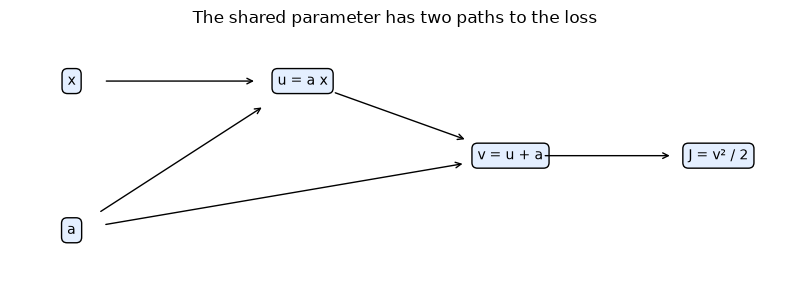

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3))
demo_positions = {"x": (0.08, 0.8), "a": (0.08, 0.2), "u = a x": (0.38, 0.8), "v = u + a": (0.65, 0.5), "J = v² / 2": (0.92, 0.5)}
for demo_name, demo_position in demo_positions.items():
    ax.text(*demo_position, demo_name, ha="center", va="center", bbox=dict(boxstyle="round,pad=0.4", facecolor="#e4efff"))
for demo_start, demo_end in [("x", "u = a x"), ("a", "u = a x"), ("a", "v = u + a"), ("u = a x", "v = u + a"), ("v = u + a", "J = v² / 2")]:
    ax.annotate("", xy=demo_positions[demo_end], xytext=demo_positions[demo_start], arrowprops=dict(arrowstyle="->", shrinkA=25, shrinkB=35))
ax.set(xlim=(0, 1), ylim=(0, 1), title="The shared parameter has two paths to the loss")
ax.axis("off")
fig.tight_layout()
plt.show()

This next cell compares activation curves and their **local** slopes, not a trained network's complete gradients. A chain multiplies such slopes, so repeatedly small factors can make early-layer sensitivities tiny.

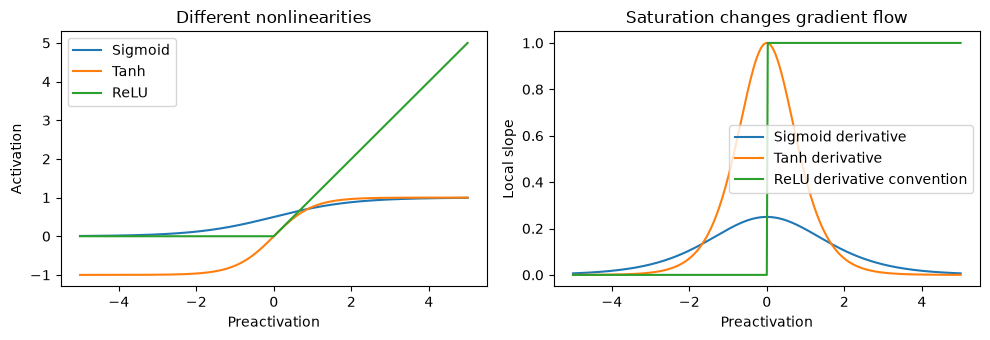

In [7]:
demo_z = np.linspace(-5.0, 5.0, 401)
demo_sigmoid = 1.0 / (1.0 + np.exp(-demo_z))
demo_tanh = np.tanh(demo_z)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(demo_z, demo_sigmoid, label="Sigmoid")
axes[0].plot(demo_z, demo_tanh, label="Tanh")
axes[0].plot(demo_z, np.maximum(0, demo_z), label="ReLU")
axes[0].set(xlabel="Preactivation", ylabel="Activation", title="Different nonlinearities")
axes[1].plot(demo_z, demo_sigmoid * (1 - demo_sigmoid), label="Sigmoid derivative")
axes[1].plot(demo_z, 1 - demo_tanh**2, label="Tanh derivative")
axes[1].plot(demo_z, (demo_z > 0).astype(float), label="ReLU derivative convention")
axes[1].set(xlabel="Preactivation", ylabel="Local slope", title="Saturation changes gradient flow")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

### Exercise 5.13 — Vary the finite-difference scale

**Type:** Experimental · **Answer:** Code

On a fixed tiny tanh network with fixed data, evaluate your gradient checker for perturbations from $10^{-2}$ to $10^{-7}$. Plot absolute and relative errors, and repeat after scaling the parameters.

**Expected outcome:** A reproducible error-versus-perturbation study with an explanation of approximation error, roundoff, and near-zero gradient norms. Do not assume the smallest perturbation wins.

In [ ]:
# Your code for Exercise 5.13.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.13**

Keep the data and parameter direction fixed; change one perturbation setting at a time.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.13**

Use **5.10–5.12**, including their fixed tiny data and parameters. The scaled networks are separate fixed states, not training runs.

~~~python
import matplotlib.pyplot as plt

ref_steps = np.logspace(-2, -7, 6)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ref_scale in (1.0, 5.0, 20.0):
    ref_scaled = {k: ref_scale * v for k, v in ref_bp_parameters.items()}
    ref_errors = [
        check_network_gradients(ref_scaled, ref_bp_X, ref_bp_Y, step=s)["overall"]
        for s in ref_steps
    ]
    for ref_axis, ref_metric in zip(
        axes, ("max_absolute_error", "relative_error")
    ):
        ref_axis.loglog(
            ref_steps,
            [max(e[ref_metric], 1e-18) for e in ref_errors],
            marker="o", label=f"parameter scale {ref_scale:g}",
        )
        ref_axis.set(xlabel="Central-difference step", ylabel=ref_metric)
        ref_axis.legend()
    print(ref_scale, list(zip(ref_steps, ref_errors)))
fig.tight_layout()
plt.show()
~~~

For smooth functions, central differences usually have a truncation term of order $\epsilon^2$ locally. Very small steps subtract nearly equal floating-point losses and amplify roundoff. Scaling can move tanh into saturation or alter curvature; inspect both errors and gradient magnitudes before interpreting a relative error. The exact minimum and curve shape must come from the run, and need not be monotonic.

</details>

### Exercise 5.14 — Investigate sensitivity without training

**Type:** Experimental · **Answer:** Code

For a fixed small network, vary the magnitude of hidden biases so tanh units move from their central region into saturation. Record hidden activations, output probabilities, and layer-wise gradient norms on the same batch.

**Expected outcome:** A labeled plot or table connecting activation regimes to gradient flow. Keep data and other parameters fixed so the comparison has an interpretable cause.

In [ ]:
# Your code for Exercise 5.14.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.14**

Record the tanh slope as well as each layer's gradient norm.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.14**

Use **5.10–5.12** and their fixed batch. Only the hidden biases change; the alternating signs push different units toward opposite saturation directions.

~~~python
ref_sensitivity_rows = []
for ref_bias_magnitude in (0.0, 1.0, 3.0, 7.0):
    ref_state = {k: v.copy() for k, v in ref_bp_parameters.items()}
    ref_state["b1"] = ref_bias_magnitude * np.array([1.0, -1.0])
    ref_P, ref_cache = network_forward(ref_bp_X, ref_state)
    ref_gradients = network_backward(ref_cache, ref_bp_Y)
    ref_row = (
        ref_bias_magnitude, float(np.mean(np.abs(ref_cache["A1"]))),
        float(np.mean(1 - ref_cache["A1"]**2)), float(ref_P.mean()),
        float(np.linalg.norm(ref_gradients["W1"])),
        float(np.linalg.norm(ref_gradients["W2"])),
    )
    ref_sensitivity_rows.append(ref_row)
    print("bias, |hidden|, tanh slope, mean p, ||dW1||, ||dW2||:", ref_row)
    print("hidden activations:", ref_cache["A1"], "probabilities:", ref_P)
ref_table = np.array(ref_sensitivity_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ref_table[:, 0], ref_table[:, 1:4], marker="o")
axes[0].legend(["Mean |hidden|", "Mean tanh slope", "Mean probability"])
axes[1].semilogy(ref_table[:, 0], np.maximum(ref_table[:, 4:], 1e-18), marker="o")
axes[1].legend(["||dW1||", "||dW2||"])
for ax in axes:
    ax.set_xlabel("Hidden bias magnitude")
fig.tight_layout()
plt.show()
~~~

The local factor $1-A_1^2$ suppresses the early-layer sensitivity near saturation. Output gradients also depend on changed hidden features and probabilities, so they need not shrink in parallel. This is a controlled intervention on biases, but not an isolation of the activation slope from every other forward effect.

</details>

## 7. Interpretation and critical analysis

A matching gradient check establishes agreement between two ways of differentiating the **implemented scalar objective** at selected parameter values. It does not establish that the objective expresses the intended problem, that the data split is valid, or that training will generalize. Two routines sharing the same unintended loss convention can agree perfectly.

Common mistakes are mixing transposes from another matrix convention, forgetting the intercept reduction, averaging twice, overwriting a shared contribution, mutating a cached array, and updating output weights before differentiating earlier layers. Check shapes and small hand-calculated examples before trusting a large loss curve.

### Exercise 5.15 — Diagnose an apparently plausible backward pass

**Type:** Critical · **Answer:** Markdown

A network trains slowly and has correctly shaped gradients. Its numerical check differs by approximately a factor equal to the batch size. Propose an investigation of the loss and gradient normalization, and explain why correct shapes alone cannot resolve it.

**Expected outcome:** A specific debugging plan that compares the exact same objective and parameter snapshot.

**Your response to Exercise 5.15**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.15**

Compare the code to one written scalar objective before changing learning rates.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.15**

A useful investigation is:

1. Freeze parameters and a small batch. Write the scalar loss exactly as evaluated, including its observation reduction and any penalty.
2. Recompute central differences of that same loss at that snapshot. Ensure perturbations are restored and no training update occurs during checking.
3. Trace where the factor $1/n$ enters. For mean binary cross-entropy it belongs in $(P-Y)/n$ once. Check for a later mean of sensitivities, another division in a matrix product, or a mismatch between a summed numerical loss and averaged analytical loss.
4. Inspect weights and biases separately. A duplicate division in only weight gradients gives a different pattern from a globally scaled objective.
5. Repeat with batch sizes one, two, and a different larger size. A discrepancy tracking $n$ supports the normalization hypothesis; correct shapes alone say nothing about this scaling.

Do not repair the symptom by multiplying gradients until the objective and derivative conventions agree. With an unaveraged regularizer, an extra data average may also change the intended relative penalty strength.

</details>

### Exercise 5.16 — State what a successful check proves

**Type:** Critical · **Answer:** Markdown

Your analytical and numerical gradients agree on one tiny network. List two additional checks needed before using the implementation for a larger experiment, and one scientific claim that gradient checking cannot establish.

**Expected outcome:** A bounded interpretation of numerical verification rather than an unqualified correctness claim.

**Your response to Exercise 5.16**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.16**

A successful check concerns a specific function at specific inputs and parameters.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.16**

Two additional checks are:

- Repeat coordinate checks across several seeded smooth parameter states, batch sizes including one, and hidden widths. Include biases and every weight, not only selected coordinates. Use several perturbation sizes and inspect absolute as well as relative error.
- Check the public contracts and numerical behavior: reject incompatible shapes and nonbinary labels, prevent accidental target broadcasting, preserve parameters during differentiation, and evaluate extreme logits with a stable finite loss. For ReLU, handle corner points separately from smooth checks.

Other useful evidence includes a small negative-gradient step lowering a smooth loss for a sufficiently small rate. None of these establishes that a larger network will optimize reliably or generalize to unseen data. Those claims require appropriately designed experiments and held-out evaluation.

</details>

## 8. Review questions and knowledge checks

### Exercise 5.17 — Explain reuse and direction

**Type:** Conceptual · **Answer:** Markdown

Why does the reverse pass start from a scalar loss? Why are intermediate forward values cached? Explain why a shared parameter receives a sum of contributions and how this relates to the row sum in a bias gradient.

**Expected outcome:** A connected explanation from scalar paths to batched matrices.

**Your response to Exercise 5.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.17**

All reverse sensitivities describe changes in the same scalar quantity.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.17**

For a scalar objective, the reverse pass starts with $\partial J/\partial J=1$ and accumulates how every intermediate and parameter influences that objective. A vector output would need a specified scalar combination or repeated seeds to obtain the corresponding derivatives.

The forward cache supplies the actual activation values, inputs, and parameter snapshot needed by local rules. Recomputing is possible, but must reproduce the same state; caching avoids needless repeated work and accidental use of updated parameters.

If a parameter is reused, changing it changes every occurrence simultaneously. The total derivative is therefore the sum of the contributions along those paths. A bias entry is the same scalar reused for every observation in one output column, so its gradient is the row sum of preactivation sensitivities. Matrix multiplication performs analogous sums across connected units.

</details>

### Exercise 5.18 — Extend one local rule

**Type:** Mathematical · **Answer:** Markdown

For a hidden activation $A=\phi(Z)$ and an already known sensitivity $G=\partial J/\partial A$, derive $\partial J/\partial Z$ entry by entry. Explain why entrywise multiplication, rather than matrix multiplication, is appropriate.

**Expected outcome:** A local chain-rule derivation with matching shapes and no unstated cross-coordinate dependencies.

**Your response to Exercise 5.18**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 5.18**

An elementwise activation connects each output entry only to its corresponding input entry.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 5.18**

For $A_{ij}=\phi(Z_{ij})$, changing $Z_{ij}$ affects $A_{ij}$ and no other activation entry. The multivariable chain rule gives
$$
\frac{\partial J}{\partial Z_{ij}}
=\sum_{r,s}\frac{\partial J}{\partial A_{rs}}
                 \frac{\partial A_{rs}}{\partial Z_{ij}}
=G_{ij}\phi'(Z_{ij}).
$$
All terms other than $r=i,s=j$ vanish. Collecting the entries gives $\partial J/\partial Z=G\odot\phi'(Z)$, with exactly the shape of $Z$. Matrix multiplication would sum cross-coordinate products and generally change the shape or the dependence being represented. This rule assumes an elementwise activation; an operation coupling coordinates needs its own derivative rule.

</details>

## 9. Summary and next learning steps

Backpropagation combines small, local derivatives in reverse dependency order. Contributions from multiple paths add; affine layers produce matrix products and bias reductions; entrywise activations produce entrywise derivative factors. A precise averaging convention prevents batch-size errors. Numerical gradient checks provide an independent local diagnostic.

Before continuing, check a shared-variable graph, every weight and bias of a tiny tanh network, and the behavior near saturation. Next: [Multilayer Perceptron](multilayer-perceptron.ipynb) combines these pieces into complete experiments with one and two hidden layers, nonlinear representation, validation, and careful interpretation.